<a href="https://colab.research.google.com/github/yulunwu000/artemis-lunar-plasma/blob/main/Sawyer_plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pyspedas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


SAWYER PLOT A B C

15-Nov-26 17:29:43: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

15-Nov-26 17:29:43: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
15-Nov-26 17:29:54: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

15-Nov-26 17:29:54: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
15-Nov-26 17:30:04: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.u

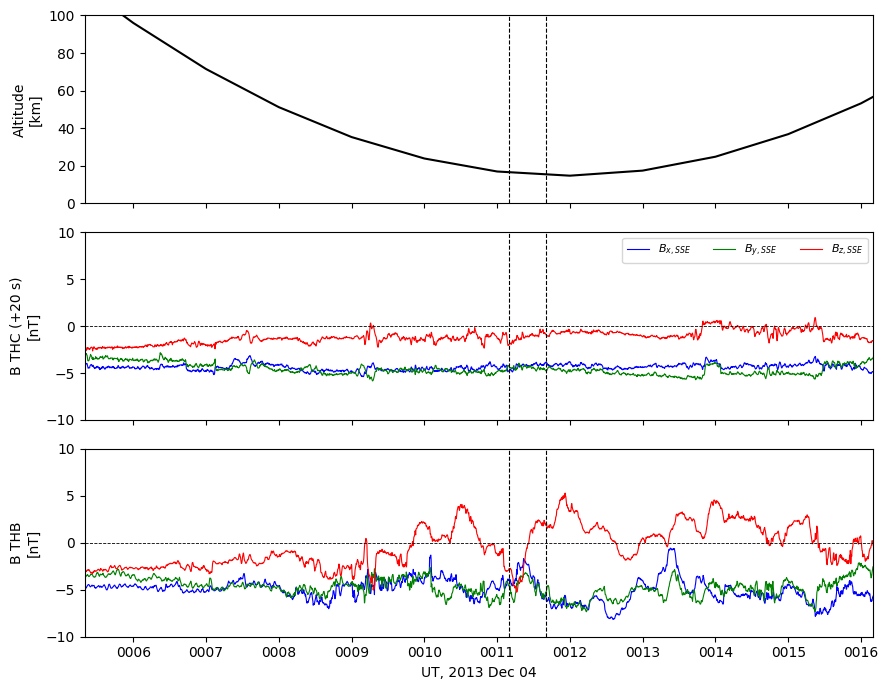

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspedas
from pyspedas import get_data
from pyspedas.projects import themis

trange = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
trange_load = ['2013-12-04/00:00', '2013-12-04/00:20']
R_moon = 1737.4
res = 'fgl'
lag = 20 #shift applied to THC

#load
themis.state(trange=trange_load, probe='b', varnames=['thb_pos_gse'], time_clip=True)
themis.fgm(trange=trange_load, probe=['b', 'c'], varnames=[f'thb_{res}_gse', f'thc_{res}_gse'], time_clip=True)

#GSE -> SSE

pyspedas.set_coords('thb_pos_gse', 'GSE')
themis.gse2sse('thb_pos_gse', 'thb_pos_sse', variable_type='pos')
themis.gse2sse(f'thb_{res}_gse', 'thb_b_sse')
themis.gse2sse(f'thc_{res}_gse', 'thc_b_sse')

pos = get_data('thb_pos_sse')
bb = get_data('thb_b_sse')
bc = get_data('thc_b_sse')

alt = np.linalg.norm(pos.y, axis=1) - R_moon

#plot
t_pos = pd.to_datetime(pos.times, unit='s')
t_b = pd.to_datetime(bb.times, unit='s')
t_c = pd.to_datetime(bc.times + lag, unit='s')

fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True)

ax[0].plot(t_pos, alt, 'k')
ax[0].set_ylim(0, 100)
ax[0].set_ylabel('Altitude\n[km]')

cols = ['b', 'g', 'r']
names = ['$B_{x,SSE}$', '$B_{y,SSE}$', '$B_{z,SSE}$']
for i in range(3):
    ax[1].plot(t_c, bc.y[:, i], color=cols[i], lw=0.8, label=names[i])
    ax[2].plot(t_b, bb.y[:, i], color=cols[i], lw=0.8)

for a in ax[1:]:
    a.axhline(0, color='k', ls='--', lw=0.6)
    a.set_ylim(-10, 10)
ax[1].set_ylabel(f'B THC (+{lag} s)\n[nT]')
ax[2].set_ylabel('B THB\n[nT]')
ax[1].legend(loc='upper right', ncol=3, fontsize=8)

# dashed lines
for t in ['2013-12-04 00:11:10', '2013-12-04 00:11:40']:
    for a in ax:
        a.axvline(pd.to_datetime(t), color='k', ls='--', lw=0.8)

ax[2].set_xlim(pd.to_datetime(trange[0].replace('/', ' ')), pd.to_datetime(trange[1].replace('/', ' ')))
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
ax[2].set_xlabel('UT, 2013 Dec 04')

plt.tight_layout()
plt.show()

In [ ]:
themis.fgm(trange=trange_load, probe='b', varnames=['thb_fgl_gse'], suffix='_raw')

d = get_data('thb_fgl_gse_raw')
dt = np.diff(d.times)
print('repeats:', np.sum(dt == 0), ' backward jumps:', np.sum(dt < 0))
print(pd.to_datetime(d.times[np.where(dt < 0)[0]], unit='s')[:10])

15-Nov-26 17:27:11: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

15-Nov-26 17:27:11: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
15-Nov-26 17:27:21: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



repeats: 0  backward jumps: 1
DatetimeIndex(['2013-12-04 19:18:09.612548828'], dtype='datetime64[ns]', freq=None)


SAWYER PLOT d and e


15-Nov-26 18:01:30: File is current: themis_data/thb/l2/esa/2013/thb_l2_esa_20131204_v01.cdf


thb_peib_en_eflux: dropped 0 empty channels and 0 spectra
thb_peeb_en_eflux: dropped 0 empty channels and 0 spectra


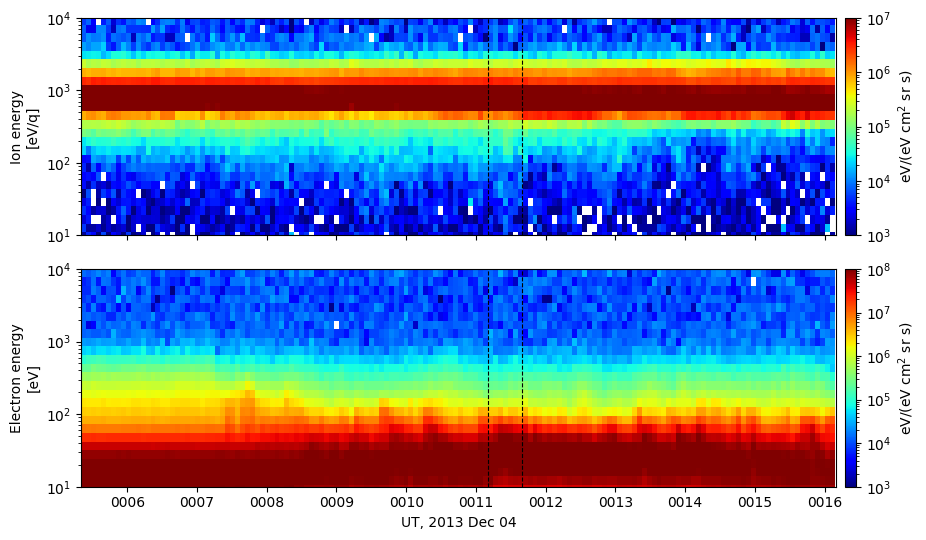

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from pyspedas import get_data
from pyspedas.projects import themis

trange = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
mode = 'b'   # 'r' = reduced (~3 s, always on), 'b' = burst, 'f' = full (slow cadence)

ion = f'thb_pei{mode}_en_eflux'
ele = f'thb_pee{mode}_en_eflux'
themis.esa(trange=trange, probe='b', varnames=[ion, ele], time_clip=True)


def spec(ax, name, vmin, vmax, label):
    d = get_data(name)
    t = mdates.date2num(pd.to_datetime(d.times, unit='s'))
    flux = np.where(d.y > 0, d.y, np.nan)
    en = d.v
    if en.ndim == 1:
        en = np.tile(en, (len(t), 1))

    #put Nans in white
    en = np.where(en > 0, en, np.nan)
    use_e = ~np.all(np.isnan(en), axis=0)
    en, flux = en[:, use_e], flux[:, use_e]
    use_t = np.all(np.isfinite(en), axis=1)
    en, flux, t = en[use_t], flux[use_t], t[use_t]
    print(f'{name}: dropped {np.sum(~use_e)} empty channels and {np.sum(~use_t)} spectra')

    tt = np.tile(t[:, None], (1, en.shape[1]))

    im = ax.pcolormesh(tt, en, flux, shading='nearest', cmap='jet',
                       norm=LogNorm(vmin=vmin, vmax=vmax))
    ax.set_yscale('log')
    ax.set_ylim(10, 1e4)
    ax.set_ylabel(label)
    cb = plt.colorbar(im, ax=ax, pad=0.01)
    cb.set_label('eV/(eV cm$^2$ sr s)')


fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

spec(ax[0], ion, 1e3, 1e7, 'Ion energy\n[eV/q]')
spec(ax[1], ele, 1e3, 1e8, 'Electron energy\n[eV]')

# dashed lines
for t in ['2013-12-04 00:11:10', '2013-12-04 00:11:40']:
    for a in ax:
        a.axvline(pd.to_datetime(t), color='k', ls='--', lw=0.8)

ax[1].set_xlim(pd.to_datetime(trange[0].replace('/', ' ')), pd.to_datetime(trange[1].replace('/', ' ')))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
ax[1].set_xlabel('UT, 2013 Dec 04')

plt.tight_layout()
plt.show()

17-Nov-26 12:46:26: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

17-Nov-26 12:46:26: File is current: themis_data/thb/l2/esd/2013/thb_l2_esa_peib_20131204_v01.cdf
17-Nov-26 12:46:37: /tmp/ipykernel_1601/765138117.py:75: RuntimeWarning: Mean of empty slice
  f_sw = np.nanmean(np.where(fi[sw] > 0, fi[sw], np.nan), axis=0)

17-Nov-26 12:46:37: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peib: modes used en=[1] an=[1], phi offset 0.0 to 0.0 deg
ion beam direction x = -0.97  ->  look_dir = False


17-Nov-26 12:46:37: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

17-Nov-26 12:46:37: File is current: themis_data/thb/l2/esd/2013/thb_l2_esa_peeb_20131204_v01.cdf
17-Nov-26 12:46:47: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peeb: modes used en=[1] an=[0], phi offset 0.0 to 0.0 deg


17-Nov-26 12:46:47: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

17-Nov-26 12:46:47: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
17-Nov-26 12:46:57: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

17-Nov-26 12:46:57: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

17-Nov-26 12:4

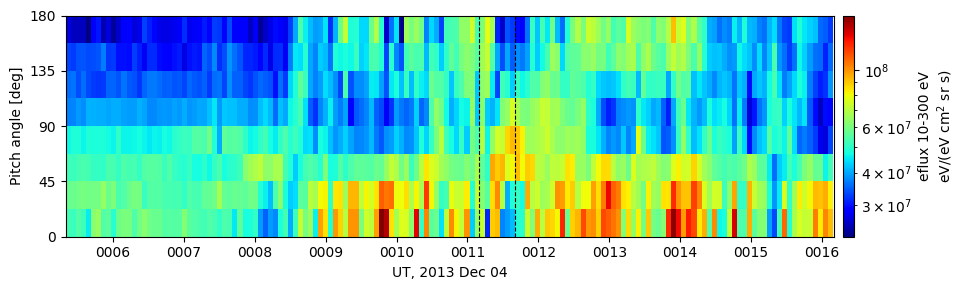

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import cdflib
from pyspedas import get_data, time_double
from pyspedas.projects import themis

trange = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
emin, emax = 10, 300     #maybe same as paper? maybe 10, 1000? not specified in paper really
pa_step = 22.5             # width of the pitch angle bins that matches the instruments resolution, any smaller and youre making up data points kinda

#reads 3D electron distribution
def read_dist(datatype):

    path = themis.esd(trange=trange, probe='b', datatype=datatype, downloadonly=True)[0]
    cdf = cdflib.CDF(path)

    t0 = np.array(cdf.varget('time'), dtype=float)       # start of each spin (unix s)
    t1 = np.array(cdf.varget('end_time'), dtype=float)   # end of each spin
    flux = np.array(cdf.varget('eflux'), dtype=float)    # (time, 32 energies, 176 angles)
    good = np.array(cdf.varget('bins')) > 0               # which bins actually have data
    en_ind = np.array(cdf.varget('en_ind')).astype(int)
    an_ind = np.array(cdf.varget('an_ind')).astype(int)
    dphi = np.array(cdf.varget('phi_offset'), dtype=float) + np.array(cdf.varget('eclipse_dphi'), dtype=float)

    energy = np.array(cdf.varget('energy'), dtype=float)  # (32, energy modes)
    theta = np.array(cdf.varget('theta'), dtype=float)    # (32, 176, angle modes)
    phi = np.array(cdf.varget('phi'), dtype=float)
    if energy.ndim == 3:                                  # in case they're stored per record
        energy, theta, phi = energy[0], theta[0], phi[0]

    print(f'{datatype}: modes used en={np.unique(en_ind)} an={np.unique(an_ind)}, '
          f'phi offset {dphi.min():.1f} to {dphi.max():.1f} deg')

    keep = (t1 >= time_double(trange[0])) & (t0 <= time_double(trange[1]))
    if good.ndim == 2:
        good = np.broadcast_to(good, flux.shape)
    flux = np.where(good & (flux > 0) & (flux < 1e30), flux, np.nan)

    # collect the data into arays
    en = energy[:, en_ind][:, :, None].transpose(1, 0, 2) * np.ones((1, 1, flux.shape[2]))
    th = theta[:, :, an_ind].transpose(2, 0, 1)
    ph = phi[:, :, an_ind].transpose(2, 0, 1) + dphi[:, None, None]

    return t0[keep], t1[keep], flux[keep], en[keep], th[keep], ph[keep]


def directions(th, ph):
    # unit vector of each bin, in the instrument (DSL) frame
    th, ph = np.radians(th), np.radians(ph)
    return np.stack([np.cos(th) * np.cos(ph), np.cos(th) * np.sin(ph), np.sin(th)], axis=-1)


#check if theta/phi give the look direction or the particle direction?
#you could set it by hand, either look_dir=1 or -1

ti, ti1, fi, ei, thi, phi_i = read_dist('peib')
sw = ti < time_double('2013-12-04/00:07:30')
f_sw = np.nanmean(np.where(fi[sw] > 0, fi[sw], np.nan), axis=0)
k = np.unravel_index(np.nanargmax(f_sw), f_sw.shape)
i0 = np.where(sw)[0][0]
x_dir = directions(thi[i0][k], phi_i[i0][k])[0]
look_dir = x_dir > 0
print(f'ion beam direction x = {x_dir:.2f}  ->  look_dir = {look_dir}')
# doesnt work if no burst data so set it by hand

# get electrons and B
t, t_end, flux, en, th, ph = read_dist('peeb')

themis.fgm(trange=trange, probe='b', varnames=['thb_fgl_dsl'], time_clip=True)
b = get_data('thb_fgl_dsl')

# for every energy/angle bin works out the pitch angle from the bin direction and B
edges = np.arange(0, 180 + pa_step, pa_step)
mids = edges[:-1] + pa_step / 2
pad = np.full((len(t), len(mids)), np.nan)

for i in range(len(t)):
    #average B over the spin the distribution was measured in
    m = (b.times >= t[i]) & (b.times < t_end[i])
    if m.sum() == 0:
        continue
    bhat = b.y[m].mean(axis=0)
    bhat = bhat / np.linalg.norm(bhat)

    v = directions(th[i], ph[i])
    if look_dir:
        v = -v
    alpha = np.degrees(np.arccos(np.clip(v @ bhat, -1, 1)))     # (energy, angle)

    use = (en[i] >= emin) & (en[i] <= emax) & np.isfinite(flux[i])
    for j in range(len(mids)):
        sel = use & (alpha >= edges[j]) & (alpha < edges[j + 1])
        if sel.any():
            pad[i, j] = flux[i][sel].mean()

#plotting
tt = mdates.date2num(pd.to_datetime((t + t_end) / 2, unit='s'))   # choose it to be the middle of each spin

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.pcolormesh(tt, mids, pad.T, shading='nearest', cmap='jet', norm=LogNorm())
ax.set_ylim(0, 180)
ax.set_yticks([0, 45, 90, 135, 180])
ax.set_ylabel('Pitch angle [deg]')
cb = plt.colorbar(im, ax=ax, pad=0.01)
cb.set_label(f'eflux {emin}-{emax} eV\neV/(eV cm$^2$ sr s)')

for tl in ['2013-12-04 00:11:10', '2013-12-04 00:11:40']:
    ax.axvline(pd.to_datetime(tl), color='k', ls='--', lw=0.8)

ax.set_xlim(pd.to_datetime(trange[0].replace('/', ' ')), pd.to_datetime(trange[1].replace('/', ' ')))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
ax.set_xlabel('UT, 2013 Dec 04')
plt.tight_layout()
plt.show()

#panel g and h



15-Nov-26 21:30:32: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

15-Nov-26 21:30:32: File is current: themis_data/thb/l2/fit/2013/thb_l2_fit_20131204_v01.cdf
15-Nov-26 21:30:43: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

15-Nov-26 21:30:43: File is current: themis_data/thb/l2/esa/2013/thb_l2_esa_20131204_v01.cdf
15-Nov-26 21:30:53: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.u

solar wind: mean (ExB)_z = -115 km/s, mean Vi_z = -24 km/s, mean (E + Vi x B)_x = 2.2 mV/m


15-Nov-26 21:33:23: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

15-Nov-26 21:33:23: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()



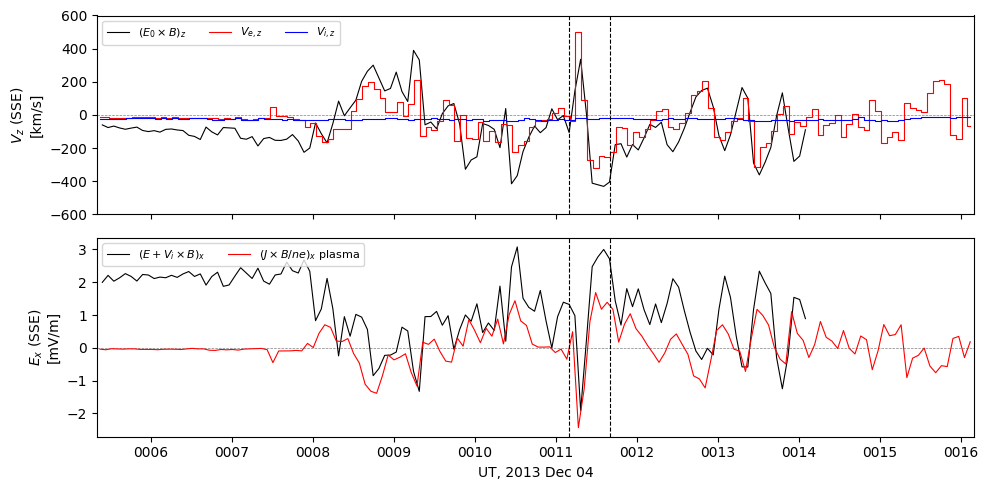

In [ ]:
#paper is using electron data that is 1 per spin (efs) which is why it looks so smooth
#efp would be the cleaned up max resolution of electron data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspedas
from pyspedas import get_data, store_data, time_double
from pyspedas.projects import themis

trange = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
switch = '2013-12-04/00:08:00'
off_sw, off_moon = 4.5, 2.5      # the different calibration methods
e_stop = '2013-12-04/00:14:05'   # get rid of the weird E data jump just like in the paper

#load data, one value per spinand burst electron data

themis.fit(trange=trange, probe='b', varnames=['thb_efs_dsl', 'thb_fgs_gse'], time_clip=True)
themis.esa(trange=trange, probe='b', varnames=['thb_peib_velocity_gse', 'thb_peeb_velocity_gse'], time_clip=True)

#calibration
e = get_data('thb_efs_dsl')
ex = e.y[:, 0] + np.where(e.times < time_double(switch), off_sw, off_moon)
ey = e.y[:, 1].copy()
ex[e.times > time_double(e_stop)] = np.nan
ey[e.times > time_double(e_stop)] = np.nan
store_data('e_dsl', data={'x': e.times, 'y': np.column_stack([ex, ey, np.zeros_like(ex)])})
pyspedas.set_coords('e_dsl', 'DSL')

# conversion to SSE
themis.dsl2gse('e_dsl', 'e_gse', probe='b')
for name_in, name_out in [('e_gse', 'e_sse'), ('thb_fgs_gse', 'b_sse'),
                          ('thb_peib_velocity_gse', 'vi_sse'), ('thb_peeb_velocity_gse', 've_sse')]:
    pyspedas.set_coords(name_in, 'GSE')
    themis.gse2sse(name_in, name_out)

E, B, Vi, Ve = get_data('e_sse'), get_data('b_sse'), get_data('vi_sse'), get_data('ve_sse')


def at(t_new, d):
    return np.column_stack([np.interp(t_new, d.times, d.y[:, k]) for k in range(3)])


#panel g
b_e = at(E.times, B)
exb = 1e3 * np.cross(E.y, b_e) / np.sum(b_e**2, axis=1)[:, None]

#panel h
e_ion = E.y + 1e-3 * np.cross(at(E.times, Vi), b_e)
# Hall term J = ne(Vi - Ve), so J x B / ne = (Vi - Ve) x B
hall = 1e-3 * np.cross(Vi.y - at(Vi.times, Ve), at(Vi.times, B))

# quick solar wind check: (ExB)_z should be close to Vi_z, (E + Vi x B)_x close to 0
sw = E.times < time_double(switch)
print(f'solar wind: mean (ExB)_z = {np.nanmean(exb[sw, 2]):.0f} km/s, '
      f'mean Vi_z = {np.nanmean(at(E.times[sw], Vi)[:, 2]):.0f} km/s, '
      f'mean (E + Vi x B)_x = {np.nanmean(e_ion[sw, 0]):.1f} mV/m')

# plot
dt = lambda t: pd.to_datetime(t, unit='s')

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

ax[0].plot(dt(E.times), exb[:, 2], 'k', lw=0.8, label=r'$(E_0 \times B)_z$')
ax[0].step(dt(Ve.times), Ve.y[:, 2], 'r', where='mid', lw=0.8, label=r'$V_{e,z}$')
ax[0].step(dt(Vi.times), Vi.y[:, 2], 'b', where='mid', lw=0.8, label=r'$V_{i,z}$')
ax[0].set_ylim(-600, 600)
ax[0].set_ylabel('$V_z$ (SSE)\n[km/s]')

ax[1].plot(dt(E.times), e_ion[:, 0], 'k', lw=0.8, label=r'$(E + V_i \times B)_x$')
ax[1].plot(dt(Vi.times), hall[:, 0], 'r', lw=0.8, label=r'$(J \times B / ne)_x$ plasma')
ax[1].set_ylabel('$E_x$ (SSE)\n[mV/m]')

for a in ax:
    a.axhline(0, color='grey', ls='--', lw=0.5, zorder=0)
    for tl in ['2013-12-04/00:11:10', '2013-12-04/00:11:40']:
        a.axvline(dt(time_double(tl)), color='k', ls='--', lw=0.8)
    a.legend(loc='upper left', fontsize=8, ncol=3)

ax[1].set_xlim(dt(time_double(trange[0])), dt(time_double(trange[1])))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
ax[1].set_xlabel('UT, 2013 Dec 04')
plt.tight_layout()
plt.show()